In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv('1stRoundFlightdata.csv')
X = df.drop(columns=["price"])
y = df["price"]
print(X.shape, y.shape)

(14431, 65) (14431,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=X["flight_class"],
)
print(X_train.shape, X_test.shape)

(11544, 65) (2887, 65)


In [4]:
def evaluate(y_true, y_pred, name="model"):
    # log-scale metrics
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # back to rupees
    true_rs, pred_rs = np.expm1(y_true), np.expm1(y_pred)
    mae_rs = mean_absolute_error(true_rs, pred_rs)
    mape = np.mean(np.abs(true_rs - pred_rs) / true_rs) * 100
    print(f"{name}: log RMSE={rmse:.4f} | log MAE={mae:.4f} | R2={r2:.4f} | "
          f"MAE=Rs {mae_rs:,.0f} | MAPE={mape:.1f}%")

# Baseline: mean log price per class, learned from the training set only
class_means = y_train.groupby(X_train["flight_class"]).mean()
baseline_pred = X_test["flight_class"].map(class_means)

evaluate(y_test, baseline_pred, "Baseline (class mean)")

Baseline (class mean): log RMSE=0.4921 | log MAE=0.3603 | R2=0.7642 | MAE=Rs 15,380 | MAPE=34.7%


In [5]:
'''
Ridge Regression.
- StandardScaler() — Standardizes features to mean 0 and standard deviation 1. 
This is important because Ridge penalizes large coefficients, so feature scales matter.
- Ridge(alpha=1.0) — Trains a linear regression model with L2 regularization.
Here, alpha controls the strength of regularization. Higher values penalize large coefficients more strongly.
- make_pipeline(...) — Ensures the scaler is fitted only on X_train 
and then applies the same transformation to X_test, preventing data leakage from scaling.
- ridge.fit(X_train, y_train) — Fits the scaler and trains the regression model.
- evaluate(...) — Evaluates predictions using your own evaluation function.
'''


from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train, y_train)
evaluate(y_test, ridge.predict(X_test), "Ridge")

Ridge: log RMSE=0.2494 | log MAE=0.1756 | R2=0.9394 | MAE=Rs 6,552 | MAPE=17.3%


In [6]:
"""
Random forest
- Builds many decision trees on random slices of the data and averages them.
- Handles nonlinear effects and interactions by itself, so no scaling is needed.
- Scored with the same evaluate() helper so it can be compared with Ridge.
"""
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
rf.fit(X_train, y_train)
evaluate(y_test, rf.predict(X_test), "Random Forest")

Random Forest: log RMSE=0.1495 | log MAE=0.0838 | R2=0.9782 | MAE=Rs 3,784 | MAPE=8.4%


In [7]:
"""
Gradient boosting
- Builds trees one after another, each one correcting the errors of the previous ones.
- HistGradientBoostingRegressor ships with sklearn, so there is nothing to install.
- No scaling needed. Scored with the same evaluate() helper as the other models.
"""
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(
    max_iter=500,
    learning_rate=0.1,
    random_state=42,
)
hgb.fit(X_train, y_train)
evaluate(y_test, hgb.predict(X_test), "Gradient Boosting")

Gradient Boosting: log RMSE=0.1539 | log MAE=0.0970 | R2=0.9769 | MAE=Rs 4,166 | MAPE=9.7%


In [8]:
"""
Tuned gradient boosting
- Randomized search tries 20 random combinations of settings.
- Each combination is scored with 5-fold cross-validation on the TRAINING set only.
- Settings searched: learning rate, number of trees, tree size,
  minimum rows per leaf, and L2 penalty (to limit overfitting).
- The best combination is refit on the full training set, then scored with
  the same evaluate() helper as the other models.
"""
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "learning_rate": [0.03, 0.05, 0.1, 0.15],
    "max_iter": [300, 500, 800],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [10, 20, 40],
    "l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
)
search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print(f"Best CV RMSE: {-search.best_score_:.4f}")

best_hgb = search.best_estimator_
evaluate(y_test, best_hgb.predict(X_test), "Tuned Gradient Boosting")

Best settings: {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.03, 'l2_regularization': 0.1}
Best CV RMSE: 0.1435
Tuned Gradient Boosting: log RMSE=0.1498 | log MAE=0.0919 | R2=0.9781 | MAE=Rs 3,958 | MAPE=9.2%


In [9]:
"""
Extra Trees
- Like a random forest, but each tree picks its split points at random
  instead of searching for the best one. That makes it faster and sometimes
  smoother, which suits data with many 0/1 columns.
- No scaling needed. Scored with the same evaluate() helper as the other models.
"""
from sklearn.ensemble import ExtraTreesRegressor

et = ExtraTreesRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    n_jobs=-1,
    random_state=42,
)
et.fit(X_train, y_train)
evaluate(y_test, et.predict(X_test), "Extra Trees")

Extra Trees: log RMSE=0.1417 | log MAE=0.0817 | R2=0.9804 | MAE=Rs 3,676 | MAPE=8.1%


In [10]:
"""
LightGBM
- Another gradient boosting library: builds trees one after another, each one
  correcting the errors of the previous ones.
- Faster than sklearn's boosting and has more settings to tune.
- Settings copied from the tuned sklearn boosting (lr 0.03, 800 trees, 63 leaves).
- No scaling needed. Scored with the same evaluate() helper as the other models.
"""
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor(
    n_estimators=800,
    learning_rate=0.03,
    num_leaves=63,
    min_child_samples=10,
    reg_lambda=0.1,
    random_state=42,
    verbose=-1,
)
lgbm.fit(X_train, y_train)
evaluate(y_test, lgbm.predict(X_test), "LightGBM")

LightGBM: log RMSE=0.1472 | log MAE=0.0886 | R2=0.9789 | MAE=Rs 3,944 | MAPE=8.9%


In [11]:
"""
XGBoost
- Another gradient boosting library, a common default for tabular data.
- subsample and colsample_bytree make each tree see only 80% of the rows and
  columns, which reduces overfitting.
- No scaling needed. Scored with the same evaluate() helper as the other models.
"""
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    n_jobs=-1,
    random_state=42,
)
xgb.fit(X_train, y_train)
evaluate(y_test, xgb.predict(X_test), "XGBoost")

XGBoost: log RMSE=0.1371 | log MAE=0.0830 | R2=0.9817 | MAE=Rs 3,750 | MAPE=8.3%


In [12]:
"""
CatBoost
- Another gradient boosting library, often strong with little tuning.
- depth controls how complex each tree is; verbose=0 silences the training log.
- No scaling needed. Scored with the same evaluate() helper as the other models.
"""
from catboost import CatBoostRegressor

cat = CatBoostRegressor(
    iterations=800,
    learning_rate=0.05,
    depth=8,
    random_state=42,
    verbose=0,
)
cat.fit(X_train, y_train)
evaluate(y_test, cat.predict(X_test), "CatBoost")

CatBoost: log RMSE=0.1441 | log MAE=0.0927 | R2=0.9798 | MAE=Rs 3,952 | MAPE=9.1%


In [14]:
"""
Cross-validation comparison (all metrics)
- Splits the TRAINING set into 5 folds: each model trains on 4 folds and is
  scored on the 5th, five times over. The test set is not touched.
- Each fold is scored on log RMSE, log MAE, R2, MAE in rupees and MAPE.
- Prints the average of each metric across the folds, plus the spread (+/-)
  for log RMSE and MAPE. Two models closer than their spread are effectively tied.
- A table sorted by log RMSE is shown at the end.
"""
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Ridge": ridge,
    "Random Forest": rf,
    "Extra Trees": et,
    "Gradient Boosting (tuned)": best_hgb,
    "LightGBM": lgbm,
    "XGBoost": xgb,
    "CatBoost": cat,
}

def cv_metrics(model, X, y, cv):
    rows = []
    for tr, va in cv.split(X):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        pred = m.predict(X.iloc[va])
        true = y.iloc[va]
        true_rs, pred_rs = np.expm1(true), np.expm1(pred)
        rows.append({
            "log RMSE": np.sqrt(mean_squared_error(true, pred)),
            "log MAE": mean_absolute_error(true, pred),
            "R2": r2_score(true, pred),
            "MAE (Rs)": mean_absolute_error(true_rs, pred_rs),
            "MAPE (%)": np.mean(np.abs(true_rs - pred_rs) / true_rs) * 100,
        })
    return pd.DataFrame(rows)

results = []
for name, model in models.items():
    f = cv_metrics(model, X_train, y_train, cv)
    mean, std = f.mean(), f.std()
    print(f"{name}: log RMSE={mean['log RMSE']:.4f} (+/- {std['log RMSE']:.4f}) | "
          f"log MAE={mean['log MAE']:.4f} | R2={mean['R2']:.4f} | "
          f"MAE=Rs {mean['MAE (Rs)']:,.0f} | MAPE={mean['MAPE (%)']:.1f}% (+/- {std['MAPE (%)']:.1f})")
    results.append({"model": name, **mean.round(4).to_dict()})

pd.DataFrame(results).sort_values("log RMSE").reset_index(drop=True)

Ridge: log RMSE=0.2503 (+/- 0.0060) | log MAE=0.1767 | R2=0.9372 | MAE=Rs 6,379 | MAPE=17.4% (+/- 0.3)
Random Forest: log RMSE=0.1425 (+/- 0.0053) | log MAE=0.0834 | R2=0.9796 | MAE=Rs 3,514 | MAPE=8.3% (+/- 0.2)
Extra Trees: log RMSE=0.1417 (+/- 0.0066) | log MAE=0.0819 | R2=0.9799 | MAE=Rs 3,410 | MAPE=8.1% (+/- 0.3)
Gradient Boosting (tuned): log RMSE=0.1418 (+/- 0.0051) | log MAE=0.0872 | R2=0.9798 | MAE=Rs 3,623 | MAPE=8.7% (+/- 0.3)
LightGBM: log RMSE=0.1425 (+/- 0.0041) | log MAE=0.0873 | R2=0.9797 | MAE=Rs 3,637 | MAPE=8.7% (+/- 0.3)
XGBoost: log RMSE=0.1364 (+/- 0.0043) | log MAE=0.0829 | R2=0.9814 | MAE=Rs 3,444 | MAPE=8.2% (+/- 0.3)
CatBoost: log RMSE=0.1456 (+/- 0.0039) | log MAE=0.0941 | R2=0.9788 | MAE=Rs 3,735 | MAPE=9.3% (+/- 0.3)


,model,log RMSE,log MAE,R2,MAE (Rs),MAPE (%)
0,XGBoost,0.1364,0.0829,0.9814,3443.6614,8.2330
1,Extra Trees,0.1417,0.0819,0.9799,3409.7870,8.0964
2,Gradient Boosting (tuned),0.1418,0.0872,0.9798,3623.4852,8.6721
3,Random Forest,0.1425,0.0834,0.9796,3514.2419,8.3347
4,LightGBM,0.1425,0.0873,0.9797,3636.8489,8.6767
5,CatBoost,0.1456,0.0941,0.9788,3734.8921,9.3008
6,Ridge,0.2503,0.1767,0.9372,6379.1638,17.3876


### On Kaggle.
- RandomForest above model, on test data result in 0.95467
- XGBoost above model, on test data result in 0.95978
- ExtraTree above model, on test data result in 0.96051

In [15]:
"""
Voting (average of models)
- VotingRegressor trains each model on the same data and averages their predictions.
- Two blends: XGBoost + Extra Trees (the two finalists, from different model
  families), and the same pair plus the tuned gradient boosting.
- Scored with the same 5-fold CV and the same five metrics as the comparison
  table (this reuses cv_metrics and cv from that cell, so run it first).
- To beat: XGBoost log RMSE 0.1364 | MAE Rs 3,444 | MAPE 8.2%
"""
from sklearn.ensemble import VotingRegressor

blends = {
    "Voting (XGB + ET)": VotingRegressor([("xgb", xgb), ("et", et)]),
    "Voting (XGB + ET + HGB)": VotingRegressor([("xgb", xgb), ("et", et), ("hgb", best_hgb)]),
}

for name, model in blends.items():
    f = cv_metrics(model, X_train, y_train, cv)
    mean, std = f.mean(), f.std()
    print(f"{name}: log RMSE={mean['log RMSE']:.4f} (+/- {std['log RMSE']:.4f}) | "
          f"log MAE={mean['log MAE']:.4f} | R2={mean['R2']:.4f} | "
          f"MAE=Rs {mean['MAE (Rs)']:,.0f} | MAPE={mean['MAPE (%)']:.1f}% (+/- {std['MAPE (%)']:.1f})")

Voting (XGB + ET): log RMSE=0.1352 (+/- 0.0053) | log MAE=0.0801 | R2=0.9817 | MAE=Rs 3,339 | MAPE=7.9% (+/- 0.3)
Voting (XGB + ET + HGB): log RMSE=0.1349 (+/- 0.0051) | log MAE=0.0810 | R2=0.9818 | MAE=Rs 3,377 | MAPE=8.0% (+/- 0.3)


------------------------

Now we have seen a prelimary performance of each model in a test train split and 
using a 5 fold cross validation. picked out the two - three best models from different family
of models and used a blend of the two to create the best model we have, using the the 1st round of 
feature engineering and data preprocessing.

the best model choose till now is a blend of XGBoost and ExtraTrees

Now we gather additional information using the best model we have so far to see where 
the model is making the most error, which features/situation is the model unable to predict
or is it an all round small errors lining up.

------------------------

In [17]:
"""
Error analysis, step 1: out-of-fold predictions from the blend
- Splits the TRAINING set into 5 folds. Each row is predicted by a model that
  never saw it, so the errors are honest.
- Blend = XGBoost + Extra Trees averaged (the same one used for the submission).
- Saves the predictions and each row's error in a table called errors, which
  the next cell will group to find where the model struggles.
- Prints the overall score first, using the same evaluate() helper.
"""
from sklearn.ensemble import VotingRegressor
from sklearn.model_selection import KFold, cross_val_predict

cv = KFold(n_splits=5, shuffle=True, random_state=42)
blend = VotingRegressor([("xgb", xgb), ("et", et)])

oof_pred = cross_val_predict(blend, X_train, y_train, cv=cv)
evaluate(y_train, oof_pred, "Blend (out-of-fold on train)")

# One row per flight: its features plus actual price, predicted price and error
errors = X_train.copy()
errors["actual_rs"] = np.expm1(y_train)
errors["pred_rs"] = np.expm1(oof_pred)
errors["error_pct"] = (errors["pred_rs"] - errors["actual_rs"]).abs() / errors["actual_rs"] * 100

print(errors["error_pct"].describe().round(1))

Blend (out-of-fold on train): log RMSE=0.1352 | log MAE=0.0801 | R2=0.9817 | MAE=Rs 3,340 | MAPE=7.9%
count    11544.0
mean         7.9
std         10.7
min          0.0
25%          1.6
50%          4.2
75%         10.0
max        156.0
Name: error_pct, dtype: float64


On Kaggle : the score of the above model is 0.96238

Half of the flights are predicted within 4.2% of the real price, and three quarters within 10%. For most flights the model is already accurate.
The average (7.9%) is much higher than the median (4.2%). That means a minority of flights have large errors and pull the average up.
The worst miss is 156%, a flight predicted at about two and a half times its real price. About a quarter of flights miss by more than 10%.

In [18]:
"""
Error analysis, step 2: where are the errors?
- Turns the one-hot columns back into readable labels (route, departure time,
  arrival time, airline prefix) and buckets days_left.
- For each group, shows how many rows it has, its mean and median error (%),
  its share of all rows, and its share of the total error.
- A group whose share of error is much bigger than its share of rows is a
  weak spot. Sorted with the worst average error first.
"""
def label(prefix):
    cols = [c for c in errors.columns if c.startswith(prefix)]
    return errors[cols].idxmax(axis=1).str.replace(prefix, "", regex=False)

errors["route"] = label("route_")
errors["departure"] = label("departure_time_")
errors["arrival"] = label("arrival_time_")
errors["airline_prefix"] = label("prefix_")
errors["class"] = errors["flight_class"].map({0: "Economy", 1: "Business"})
errors["class_stops"] = errors["class"] + " / " + errors["stops"].astype(str) + " stops"
errors["days_bucket"] = pd.cut(errors["days_left"], [0, 3, 7, 14, 30, 60],
                               labels=["1-3", "4-7", "8-14", "15-30", "31+"])

def summarize(col):
    g = errors.groupby(col, observed=True)["error_pct"].agg(
        rows="count", mean_err="mean", median_err="median")
    g["share_of_rows_%"] = g["rows"] / len(errors) * 100
    g["share_of_error_%"] = (errors.groupby(col, observed=True)["error_pct"].sum()
                             / errors["error_pct"].sum() * 100)
    return g.round(1).sort_values("mean_err", ascending=False)

for col in ["class_stops", "days_bucket", "departure", "arrival", "airline_prefix"]:
    print(f"\n--- by {col} ---")
    print(summarize(col))

print("\n--- 10 worst routes ---")
print(summarize("route").head(10))


--- by class_stops ---
                    rows  mean_err  median_err  share_of_rows_%  \
class_stops                                                       
Economy / 2 stops      1      40.5        40.5              0.0   
Business / 0 stops  2055      10.2         6.8             17.8   
Business / 1 stops  2658       9.5         4.9             23.0   
Business / 2 stops    51       7.4         5.9              0.4   
Economy / 1 stops    795       7.2         3.3              6.9   
Economy / 0 stops   5984       6.5         3.6             51.8   

                    share_of_error_%  
class_stops                           
Economy / 2 stops                0.0  
Business / 0 stops              23.0  
Business / 1 stops              27.6  
Business / 2 stops               0.4  
Economy / 1 stops                6.3  
Economy / 0 stops               42.7  

--- by days_bucket ---
             rows  mean_err  median_err  share_of_rows_%  share_of_error_%
days_bucket                 

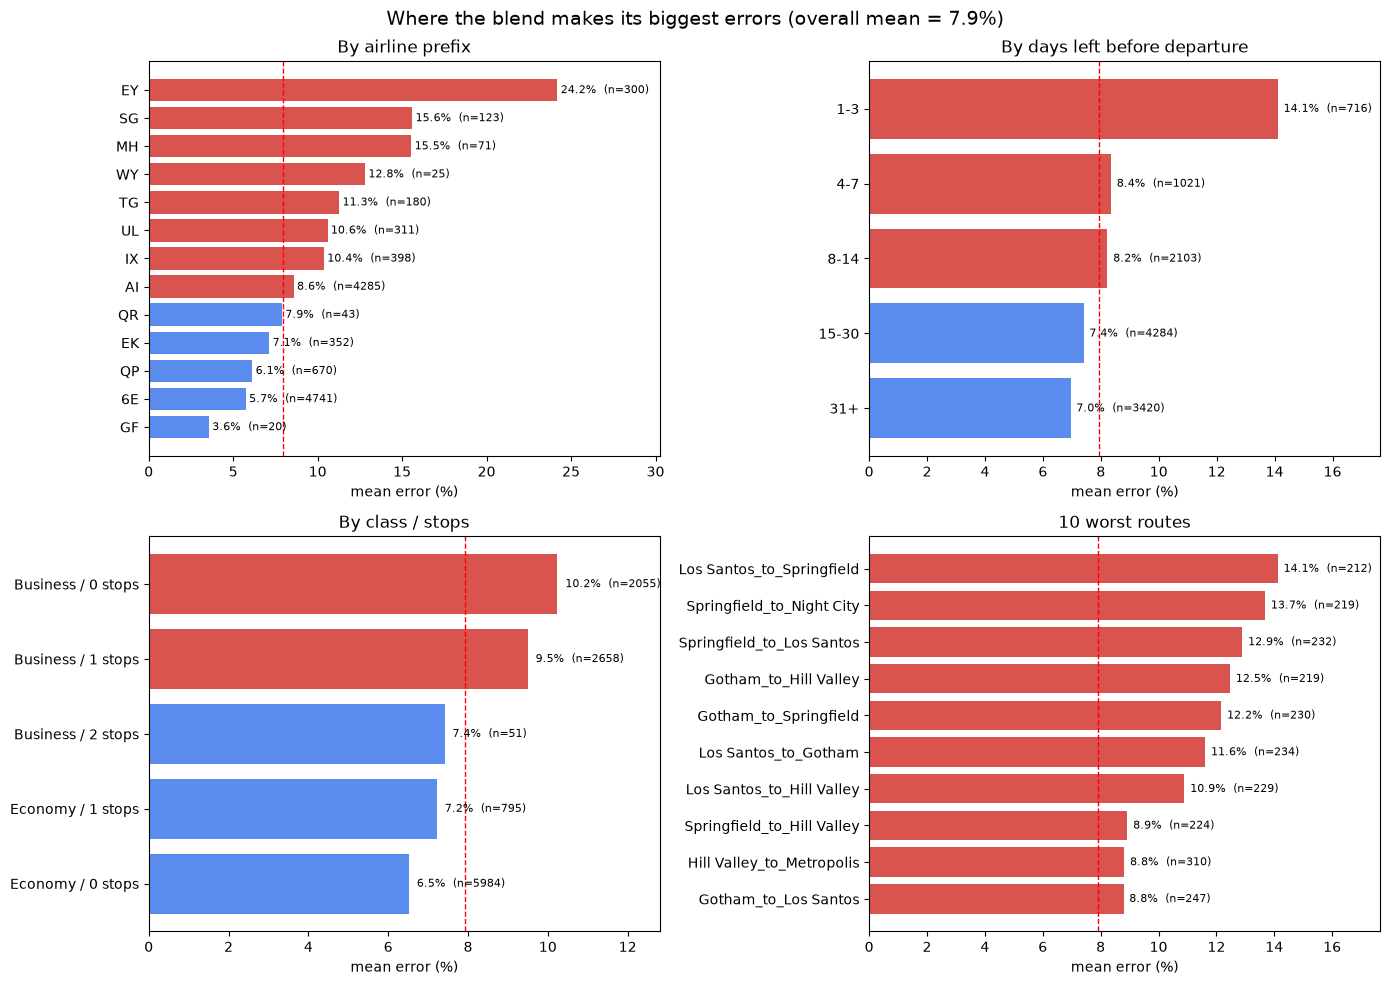

In [ ]:
"""
Error analysis, step 3: graph of the weak areas
- Four panels: airline prefix, days left, class / stops, and the 10 worst routes.
- Each bar is the mean error (%) of that group.
- The red dashed line is the overall mean error. Bars above it are red.
- The number next to each bar is how many rows are in that group.
- Groups with fewer than 10 rows are left out, because their averages are noise.
"""
import matplotlib.pyplot as plt

overall = errors["error_pct"].mean()

def panel(ax, col, title, top=None, min_rows=10):
    g = (errors.groupby(col, observed=True)["error_pct"]
               .agg(["mean", "count"])
               .query("count >= @min_rows")
               .sort_values("mean", ascending=False))
    if top:
        g = g.head(top)
    g = g.iloc[::-1]  # worst group at the top
    colors = ["#d9534f" if m > overall else "#5b8def" for m in g["mean"]]
    ax.barh(g.index.astype(str), g["mean"], color=colors)
    ax.axvline(overall, color="red", linestyle="--", linewidth=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        ax.text(m + 0.2, i, f"{m:.1f}%  (n={n})", va="center", fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("mean error (%)")
    ax.set_xlim(0, g["mean"].max() * 1.25)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
panel(axes[0, 0], "airline_prefix", "By airline prefix")
panel(axes[0, 1], "days_bucket", "By days left before departure")
panel(axes[1, 0], "class_stops", "By class / stops")
panel(axes[1, 1], "route", "10 worst routes", top=10)

fig.suptitle(f"Where the blend makes its biggest errors (overall mean = {overall:.1f}%)",
             fontsize=14)
plt.tight_layout()
plt.show()

Throught the graph we see we need to look at EY and days left (1-3) which contribute a lot of error in the data 
while also being substatial enough to not be ignored. 


In [22]:
"""
EY deep dive
1. Profile: how EY flights differ from all other airlines.
2. Bias: does the model over- or under-predict EY (signed error, %)?
3. Where inside EY the error is highest (class, stops, days left).
4. Noise check: flights with IDENTICAL features but different prices.
   A big price spread inside such groups means the features cannot explain
   the price, so only new information (e.g. flight number) could help.
"""
feat_cols = list(X_train.columns)

errors["signed_pct"] = (errors["pred_rs"] - errors["actual_rs"]) / errors["actual_rs"] * 100
errors["log_price"] = np.log1p(errors["actual_rs"])
errors["is_EY"] = np.where(errors["airline_prefix"] == "EY", "EY", "all others")

# 1. Profile
print("--- 1. Profile ---")
profile = errors.groupby("is_EY").agg(
    rows=("actual_rs", "count"),
    business_share=("flight_class", "mean"),
    mean_stops=("stops", "mean"),
    mean_duration=("duration", "mean"),
    mean_days_left=("days_left", "mean"),
    mean_price_rs=("actual_rs", "mean"),
    mean_error_pct=("error_pct", "mean"),
)
print(profile.round(2).T)

# 2. Bias
ey = errors[errors["airline_prefix"] == "EY"]
print("\n--- 2. Bias (signed error %, positive = predicted too high) ---")
print(errors.groupby("is_EY")["signed_pct"].agg(["mean", "median"]).round(1))

# 3. Inside EY
for col in ["class_stops", "days_bucket", "route"]:
    print(f"\n--- 3. EY error by {col} ---")
    t = ey.groupby(col, observed=True).agg(
        rows=("error_pct", "count"),
        mean_err=("error_pct", "mean"),
        signed=("signed_pct", "mean"),
    )
    print(t[t["rows"] >= 5].round(1).sort_values("mean_err", ascending=False).head(8))

# 4. Noise check: same features, different price?
def spread(df):
    g = df.groupby(feat_cols)["log_price"].agg(["count", "std"])
    g = g[g["count"] >= 2]
    return pd.Series({"groups": len(g), "rows_in_groups": int(g["count"].sum()),
                      "mean_price_spread_(log std)": g["std"].mean()})

print("\n--- 4. Same features, different price ---")
print(pd.DataFrame({"EY": spread(errors[errors["is_EY"] == "EY"]),
                    "all others": spread(errors[errors["is_EY"] == "all others"])}).round(3))

--- 1. Profile ---
is_EY                  EY  all others
rows               300.00    11244.00
business_share       0.91        0.40
mean_stops           1.00        0.29
mean_duration       13.83        4.07
mean_days_left      22.23       22.22
mean_price_rs   140048.59    27323.77
mean_error_pct      24.19        7.49

--- 2. Bias (signed error %, positive = predicted too high) ---
            mean  median
is_EY                   
EY           5.0     0.9
all others   0.8     1.1

--- 3. EY error by class_stops ---
                    rows  mean_err  signed
class_stops                               
Business / 1 stops   272      25.4     5.6
Economy / 1 stops     28      12.7    -0.8

--- 3. EY error by days_bucket ---
             rows  mean_err  signed
days_bucket                        
8-14           52      28.4     9.5
15-30         123      27.1     8.2
1-3            14      26.6     1.4
4-7            25      20.4    -2.5
31+            86      18.2     0.4

--- 3. EY error

the output shows

EY is a different kind of flight. 91% are business class and every one has 1 stop. The average duration is 13.8 hours against 4.1 for everything else, and the average price is Rs 140k against Rs 27k. These are the long, expensive routes, and there are only 300 of them.
The model has no consistent bias on EY. The signed error is +5% on average but only +0.9% at the median. So it isn’t always guessing too high or too low. It’s scattered in both directions.
The error is everywhere inside EY. Every days-left bucket is at 18–28%, and the routes with enough rows are at 24–44%. So there’s no corner of EY to fix, and no interaction feature will cure it.
The noise check failed for EY. Only 2 groups of EY flights shared identical features, because duration is almost unique per flight. A spread of 0.009 from 4 rows means nothing. For other airlines it worked: identical-looking flights differ in price by about 8.5% (log std 0.085).


In [30]:
"""
EY deep dive on the RAW data
1. How many distinct EY flight codes are there, and do they repeat?
2. Was EY's duration missing more often (and so filled with a median)?
3. Does the flight code explain price? Compare the price spread (std of log price)
   inside groups of: same route + class, and same flight code + class.
   If the flight-code groups are much tighter than the route groups, the flight
   number carries real information and is worth bringing back.
Shown for EY and for all other airlines side by side.
"""
import pandas as pd
import numpy as np
raw = pd.read_csv("flight_train.csv")

raw["prefix"] = raw["flight"].str.strip().str.upper().str[:2]
raw["log_price"] = np.log1p(raw["price"])
raw["route"] = raw["source_city"] + "_to_" + raw["destination_city"]
raw["group"] = np.where(raw["prefix"] == "EY", "EY", "all others")

# 1. Distinct flights and repeats
print("--- 1. How many distinct EY flights, and do they repeat? ---")
ey = raw[raw["prefix"] == "EY"]
codes = ey["flight"].str.strip().value_counts()
print("EY rows:", len(ey), "| distinct flight codes:", len(codes))
print("Rows per flight code:")
print(codes.value_counts().sort_index().rename("n_flight_codes").to_frame().T)
print(f"Share of EY rows whose flight code appears 2+ times: "
      f"{(ey['flight'].str.strip().map(codes) >= 2).mean()*100:.0f}%")

# 2. Missing duration
print("\n--- 2. Was EY duration missing (and filled by the median)? ---")
print(raw.groupby("group")["duration"]
         .apply(lambda s: s.isna().mean() * 100).round(1).rename("% duration missing"))

# 3. Does the flight code explain price?
print("\n--- 3. Does the flight code explain price? ---")
def within_std(df, keys):
    g = df.groupby(keys)["log_price"].agg(["count", "std"]).query("count >= 2")
    return pd.Series({"groups": len(g), "rows": int(g["count"].sum()),
                      "mean_log_price_std": round(g["std"].mean(), 3)})

rows = {}
for name, df in [("EY", raw[raw["group"] == "EY"]),
                 ("all others", raw[raw["group"] == "all others"])]:
    rows[(name, "overall (everything)")] = pd.Series(
        {"groups": 1, "rows": len(df), "mean_log_price_std": round(df["log_price"].std(), 3)})
    rows[(name, "same route + class")] = within_std(df, ["route", "flight_class"])
    rows[(name, "same flight code + class")] = within_std(df, ["flight", "flight_class"])
print(pd.DataFrame(rows).T)

--- 1. How many distinct EY flights, and do they repeat? ---
EY rows: 407 | distinct flight codes: 16
Rows per flight code:
count           1   2   3   7   14  21  25  28  32  39  40  56  59  63
n_flight_codes   1   1   2   1   2   1   1   1   1   1   1   1   1   1
Share of EY rows whose flight code appears 2+ times: 100%

--- 2. Was EY duration missing (and filled by the median)? ---
group
EY            19.7
all others    19.9
Name: % duration missing, dtype: float64

--- 3. Does the flight code explain price? ---
                                     groups     rows  mean_log_price_std
EY         overall (everything)         1.0    407.0               0.590
           same route + class          32.0    403.0               0.266
           same flight code + class    23.0    404.0               0.273
all others overall (everything)         1.0  15182.0               0.947
           same route + class          60.0  15182.0               0.374
           same flight code + class  1323

with the result we can conclude that EY data cannot be meaning fully 
changed right now and can just be treated as noise for the time being.


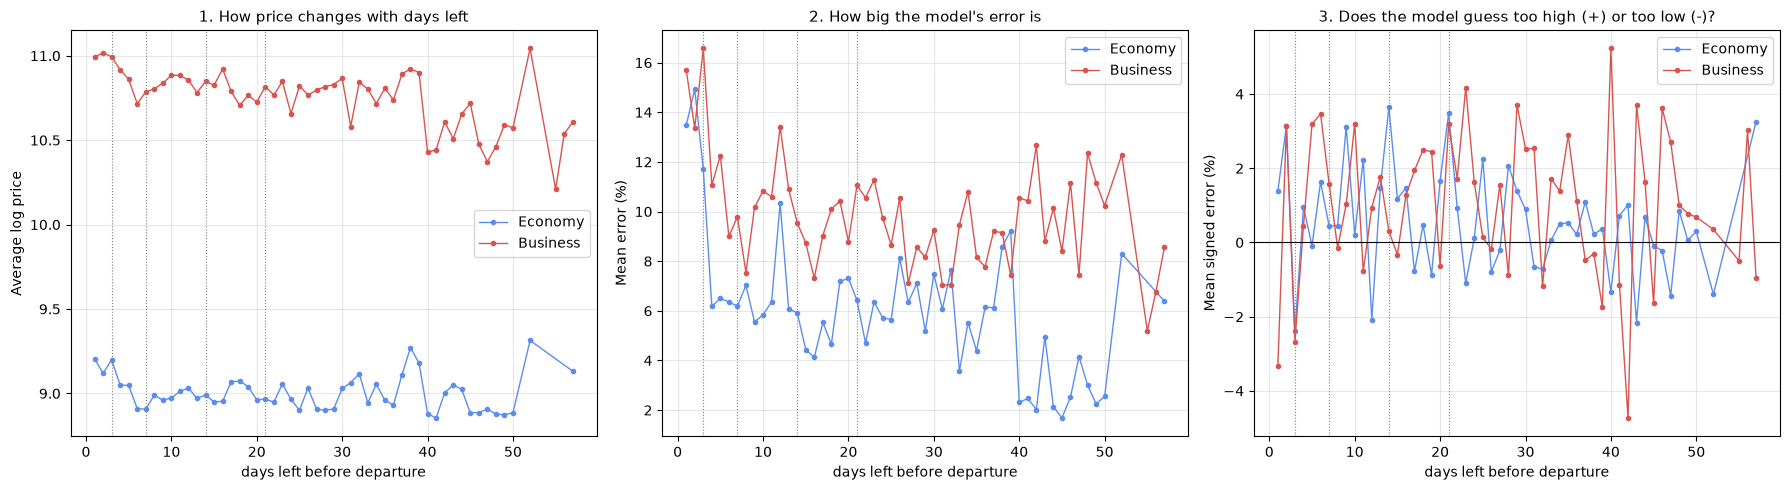

          mean_err           signed             rows        
class     Business Economy Business Economy Business Economy
days_left                                                   
1             15.7    13.5     -3.3     1.4     68.0   181.0
2             13.4    14.9      3.1     3.1     83.0   197.0
3             16.6    11.7     -2.7    -2.4     73.0   114.0
4             11.1     6.2      0.4     1.0    119.0   107.0
5             12.3     6.5      3.2    -0.1    152.0   136.0
6              9.0     6.4      3.5     1.6     72.0   178.0
7              9.8     6.2      1.6     0.4    120.0   137.0
8              7.5     7.0     -0.1     0.5     75.0   164.0
9             10.2     5.6      1.0     3.1    141.0   184.0
10            10.8     5.8      3.2     0.2    106.0   245.0
11            10.6     6.4     -0.8     2.2    101.0   134.0
12            13.4    10.3      0.9    -2.1    119.0   209.0
13            10.9     6.1      1.8     1.5    137.0   225.0
14             9.6     5

In [ ]:
"""
Days-left analysis
- Panel 1: average log price for each days_left value (economy vs business).
  Look for bends or jumps: that is where airlines change their pricing.
- Panel 2: the model's mean error (%) for each days_left value.
  Shows exactly which days the model struggles on.
- Panel 3: signed error (%): above 0 = model guesses too high, below 0 = too low.
  A steady push in one direction means the model is missing a pattern.
- Grey dotted lines mark days 3, 7, 14 and 21 (common airline pricing steps).
- A small table below prints the numbers for the last 20 days.
"""
import matplotlib.pyplot as plt

errors["log_price"] = np.log1p(errors["actual_rs"])
errors["signed_pct"] = (errors["pred_rs"] - errors["actual_rs"]) / errors["actual_rs"] * 100
errors["class"] = errors["flight_class"].map({0: "Economy", 1: "Business"})

by_day = (errors.groupby(["days_left", "class"])
                .agg(rows=("error_pct", "count"),
                     log_price=("log_price", "mean"),
                     mean_err=("error_pct", "mean"),
                     signed=("signed_pct", "mean"))
                .reset_index()
                .query("rows >= 5"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
panels = [("log_price", "Average log price", "1. How price changes with days left"),
          ("mean_err", "Mean error (%)", "2. How big the model's error is"),
          ("signed", "Mean signed error (%)", "3. Does the model guess too high (+) or too low (-)?")]
for ax, (col, ylabel, title) in zip(axes, panels):
    for cls, color in [("Economy", "#5b8def"), ("Business", "#d9534f")]:
        d = by_day[by_day["class"] == cls]
        ax.plot(d["days_left"], d[col], marker="o", markersize=3, linewidth=1, color=color, label=cls)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("days left before departure")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()
axes[2].axhline(0, color="black", linewidth=0.8)
for ax in axes:
    for d in (3, 7, 14, 21):
        ax.axvline(d, color="grey", linestyle=":", linewidth=0.8)
plt.tight_layout()
plt.show()

print(by_day[by_day["days_left"] <= 20].pivot(index="days_left", columns="class",
      values=["mean_err", "signed", "rows"]).round(1))

The graph says days left is not the problem, so there isn’t much to gain from engineering it.

Price barely changes with days left. Flights in the last 3 days cost only a bit more, and business prices drop a bit after about day 40. There’s no sharp jump or step that the model is missing.
The model already gets the average price right on every day. The bias chart stays close to zero the whole way, so the model isn’t guessing too high or too low for any range of days.
The last 3 days are just harder to predict. The error is higher there (12-17% against 6-7%), but it’s scatter. Flights vary a lot from each other in those days, and nothing in our data tells us which will be high or low.

Next we divide the class and see before in the graph we can see that 
Business class has a much higher error than economy class on average.

--- 1. Business vs economy ---
class             Business  Economy
rows                4764.0   6780.0
mean_err               9.8      6.6
median_err             5.7      3.5
signed                 1.2      0.7
mean_price_rs      60763.3   8815.1
share_of_rows_%       41.3     58.7
share_of_error_%      51.0     49.0

--- 2. Business error by airline_prefix ---
                rows  mean_err  median_err  signed
airline_prefix                                    
EY               272      25.4        18.5     5.6
QP                26      24.0        22.5     2.6
MH                70      14.8        11.0     2.6
WY                22      13.2         8.8    -1.9
TG               168      11.7        10.6     0.7
AI              2262      10.6         7.4     1.1
UL               256      10.1         4.9     1.5
QR                43       7.9         2.1    -2.3
EK               324       6.8         3.5     0.4
6E              1274       4.9         2.7     0.4
GF                20    

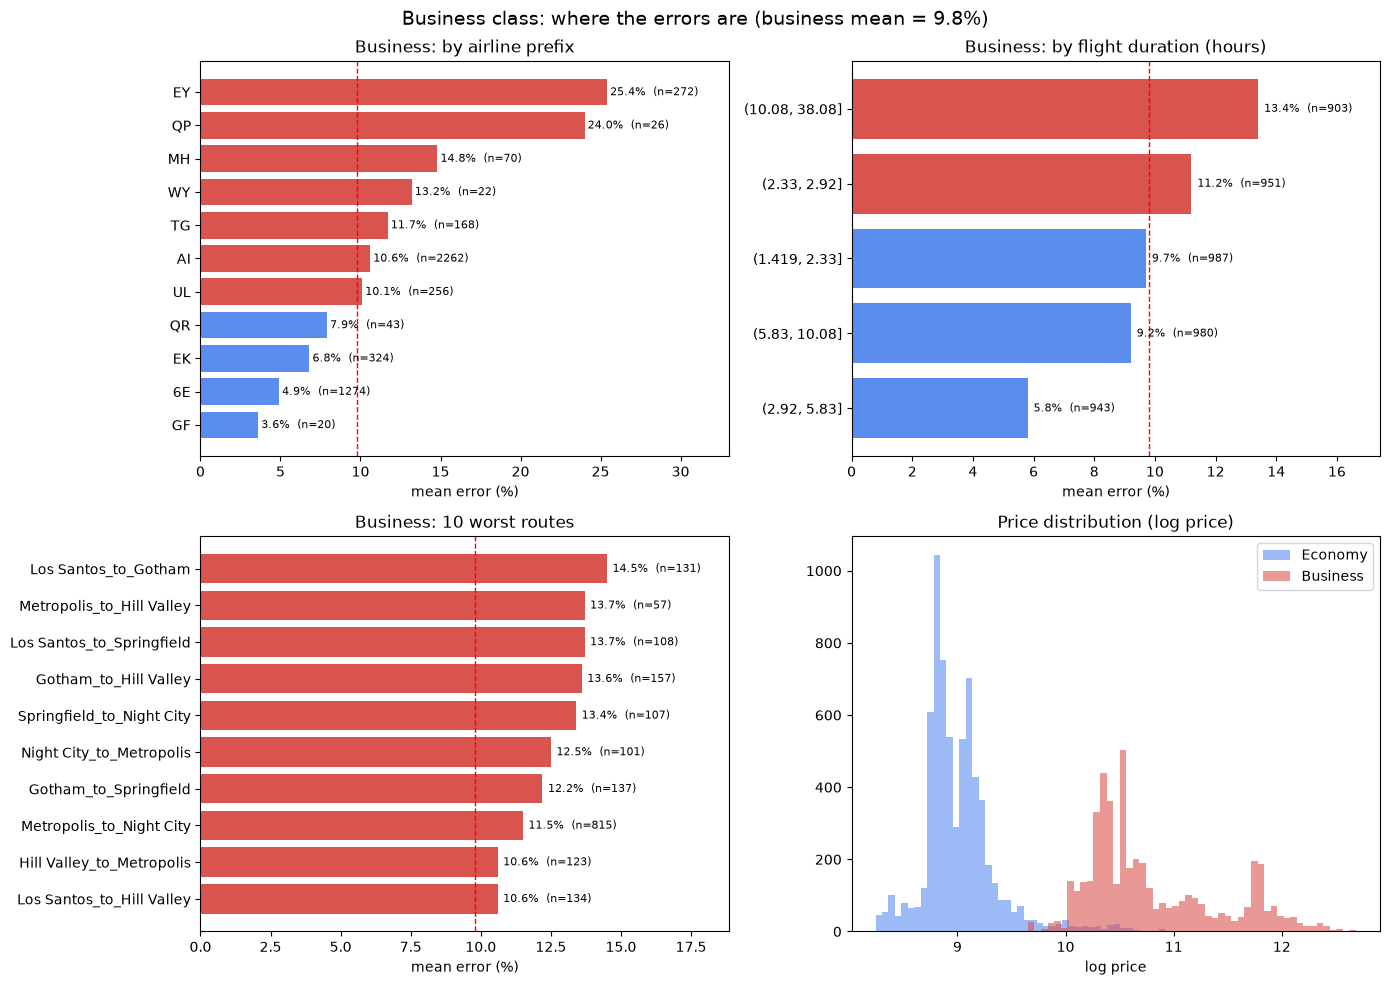

In [28]:
"""
Business class deep dive
1. Business vs economy: row share, error share, bias.
2. Inside business: error by airline prefix, stops, duration, departure,
   arrival and route (groups under 20 rows are hidden).
3. Noise check: business flights with IDENTICAL features but different prices.
4. Graphs: bars for airline / duration / worst routes (red = above the business
   average) and the price distribution of business vs economy.
"""
import matplotlib.pyplot as plt

feat_cols = list(X_train.columns)
errors["signed_pct"] = (errors["pred_rs"] - errors["actual_rs"]) / errors["actual_rs"] * 100
errors["log_price"] = np.log1p(errors["actual_rs"])
errors["class"] = errors["flight_class"].map({0: "Economy", 1: "Business"})
biz = errors[errors["class"] == "Business"].copy()
biz["duration_bucket"] = pd.qcut(biz["duration"], 5, duplicates="drop")

# 1. Business vs economy
print("--- 1. Business vs economy ---")
t = errors.groupby("class").agg(rows=("error_pct", "count"), mean_err=("error_pct", "mean"),
                                median_err=("error_pct", "median"), signed=("signed_pct", "mean"),
                                mean_price_rs=("actual_rs", "mean"))
t["share_of_rows_%"] = t["rows"] / len(errors) * 100
t["share_of_error_%"] = errors.groupby("class")["error_pct"].sum() / errors["error_pct"].sum() * 100
print(t.round(1).T)

# 2. Inside business
def summarize(col, min_rows=20):
    g = biz.groupby(col, observed=True).agg(rows=("error_pct", "count"), mean_err=("error_pct", "mean"),
                                            median_err=("error_pct", "median"), signed=("signed_pct", "mean"))
    return g[g["rows"] >= min_rows].round(1).sort_values("mean_err", ascending=False)

for col in ["airline_prefix", "stops", "duration_bucket", "departure", "arrival"]:
    print(f"\n--- 2. Business error by {col} ---")
    print(summarize(col))
print("\n--- 2. Business: 10 worst routes ---")
print(summarize("route").head(10))

# 3. Noise check
def spread(df):
    g = df.groupby(feat_cols)["log_price"].agg(["count", "std"]).query("count >= 2")
    return pd.Series({"groups": len(g), "rows_in_groups": int(g["count"].sum()),
                      "mean_log_price_std": g["std"].mean()})
print("\n--- 3. Same features, different price ---")
print(pd.DataFrame({"Business": spread(biz), "Economy": spread(errors[errors["class"] == "Economy"])}).round(3))

# 4. Graphs
overall_biz = biz["error_pct"].mean()
def bars(ax, col, title, top=None):
    g = summarize(col)
    if top: g = g.head(top)
    g = g.iloc[::-1]
    ax.barh(g.index.astype(str), g["mean_err"],
            color=["#d9534f" if m > overall_biz else "#5b8def" for m in g["mean_err"]])
    ax.axvline(overall_biz, color="red", linestyle="--", linewidth=1)
    for i, (m, n) in enumerate(zip(g["mean_err"], g["rows"])):
        ax.text(m + 0.2, i, f"{m:.1f}%  (n={n})", va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel("mean error (%)")
    ax.set_xlim(0, g["mean_err"].max() * 1.3)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
bars(axes[0, 0], "airline_prefix", "Business: by airline prefix")
bars(axes[0, 1], "duration_bucket", "Business: by flight duration (hours)")
bars(axes[1, 0], "route", "Business: 10 worst routes", top=10)
for cls, color in [("Economy", "#5b8def"), ("Business", "#d9534f")]:
    axes[1, 1].hist(errors.loc[errors["class"] == cls, "log_price"], bins=50,
                    alpha=0.6, color=color, label=cls)
axes[1, 1].set_title("Price distribution (log price)")
axes[1, 1].set_xlabel("log price"); axes[1, 1].legend()
fig.suptitle(f"Business class: where the errors are (business mean = {overall_biz:.1f}%)", fontsize=14)
plt.tight_layout(); plt.show()

With the above graph we can see that the the price follows a different distribution 
and form a seperate 'hill' in price distribution although the rest of the observations are similar to the comibined data

In [29]:
"""
Testing Separate model per class
- For each of the 5 folds: train one blend on economy rows only and one on
  business rows only, then predict each class with its own model.
- Uses the same folds (cv) as the joint blend, so the scores are comparable.
- Prints the overall scores for the joint blend (oof_pred from earlier) and the
  separate blends, then the mean error (%) per class for both.
"""
from sklearn.base import clone

sep_pred = pd.Series(index=X_train.index, dtype=float)
for tr, va in cv.split(X_train):
    X_tr, y_tr = X_train.iloc[tr], y_train.iloc[tr]
    X_va = X_train.iloc[va]
    for c in [0, 1]:
        m = clone(blend).fit(X_tr[X_tr["flight_class"] == c], y_tr[X_tr["flight_class"] == c])
        mask = X_va["flight_class"] == c
        sep_pred.loc[X_va.index[mask]] = m.predict(X_va[mask])

print("Scores on the same 5 folds (out-of-fold, training set):")
evaluate(y_train, oof_pred, "One joint blend      ")
evaluate(y_train, sep_pred.values, "Separate blends/class")

true_rs = np.expm1(y_train)
rows = {}
for name, pred in [("Joint", oof_pred), ("Separate", sep_pred.values)]:
    err = (np.abs(np.expm1(pred) - true_rs) / true_rs * 100)
    rows[name] = err.groupby(X_train["flight_class"].map({0: "Economy", 1: "Business"})).mean()
print("\nMean error (%) by class:")
print(pd.DataFrame(rows).round(2))

Scores on the same 5 folds (out-of-fold, training set):
One joint blend      : log RMSE=0.1352 | log MAE=0.0801 | R2=0.9817 | MAE=Rs 3,340 | MAPE=7.9%
Separate blends/class: log RMSE=0.1351 | log MAE=0.0789 | R2=0.9817 | MAE=Rs 3,332 | MAPE=7.8%

Mean error (%) by class:
              Joint  Separate
flight_class                 
Business       9.79      9.83
Economy        6.61      6.39


The submission made on Kaggle using the above resulted in a public score of 0.96051